# Karabük Üniversitesi ders öğrenme çıktılarının yapay zekâ ile kalite kontrolü: veri analizi

Bu dosya, projede daha önce yaptığım analizleri tek yerde topluyor. Veri, Karabük Üniversitesi bilgi paketindeki Türkçe ders öğrenme çıktısı cümleleridir. Her cümle için amaç üç sınıftan birini seçmek: düzgün, belirsiz, çıktı değil. Cümle düzgünse ayrıca Bloom basamağı da bulunuyor. Bu defterde model eğitmiyorum; yalnız veriyi okuyor, sayıyor, tabloya ve grafiğe döküyorum. Sayıların çoğu vize raporundaki ön analizle (`kalite-rapor/analiz.py`, `doluluk.py`) ve final raporundaki tablolarla (`final/10_program_raporu.py`) aynı tanımlarla hesaplanıyor.

Kullandığım dosyalar (yollar bu dosyanın bulunduğu `final/` klasörüne göre):

| Dosya | İçeriği |
|---|---|
| `../veri/karabuk_ders_ciktilari.csv` | Ham veri: her satır bir öğrenme çıktısı cümlesi |
| `../kalite-rapor/analiz/doluluk.csv` | Ders sayfası başına hangi bölümlerin boş olduğu |
| `etiket2/etiket_kesin_800.csv` | Elle onaylanmış 795 etiketli cümle (cevap anahtarı) |
| `tum_etiketler.csv` | Modelin bütün cümlelere verdiği etiketler |
| `sonuc_02.json`, `sonuc_03.json`, `sonuc_04.json` | Kural, TF-IDF ve BERTurk yöntemlerinin sonuçları |
| `llm/gpt_tahmin.csv`, `llm/haiku2_tahmin.csv` | İki büyük modelin 100 test cümlesindeki tahminleri |

## Hazırlık

Bu adımda kitaplıkları yüklüyor, grafik görünümünü ve dosya yollarını ayarlıyorum. Sonraki hücrelerde kullanacağım küçük yardımcı fonksiyonları da burada topluyorum ki her hücre tek iş yapsın.

In [1]:
import json
import re
import warnings
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 20)

# Grafik görünümü (vize raporundaki ayarlarla aynı; Türkçe harfler için Segoe UI, yoksa DejaVu Sans)
MAVI, TURUNCU, YESIL, GRI = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
MUREKKEP, MUREKKEP2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUREKKEP2,
    "xtick.color": MUREKKEP2, "ytick.color": MUREKKEP2,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 100, "figure.autolayout": True,
})

# Dosya yolları (bu defterin bulunduğu final/ klasörüne göre)
YOL_HAM = "../veri/karabuk_ders_ciktilari.csv"
YOL_DOLULUK = "../kalite-rapor/analiz/doluluk.csv"
YOL_ETIKET = "etiket2/etiket_kesin_800.csv"
YOL_TUM = "tum_etiketler.csv"
YOL_GPT = "llm/gpt_tahmin.csv"
YOL_HAIKU = "llm/haiku2_tahmin.csv"

BLOOM = ["HATIRLAMA", "ANLAMA", "UYGULAMA", "ANALIZ", "DEGERLENDIRME", "YARATMA", "BILISSEL_DEGIL"]
BLOOM_AD = ["Hatırlama", "Anlama", "Uygulama", "Analiz", "Değerlendirme", "Yaratma", "Bilişsel değil"]
KALITE = ["DUZGUN", "BELIRSIZ", "CIKTI_DEGIL"]
KALITE_AD = {"DUZGUN": "Düzgün", "BELIRSIZ": "Belirsiz", "CIKTI_DEGIL": "Çıktı değil"}


def sayi(n):
    """Binlik ayracı nokta olan tam sayı: 14912 -> 14.912"""
    return f"{int(n):,}".replace(",", ".")


def ondalik(x, k=1):
    """Ondalık ayracı virgül olan sayı: 8.1 -> 8,1"""
    return f"{x:.{k}f}".replace(".", ",")


def kucuk_harf(s):
    return s.replace("I", "ı").replace("İ", "i").lower()


def kisalt(s, n=44):
    """Birim adını okunur hale getirir: BÜYÜK HARF -> Baş Harfler Büyük, uzunsa kısaltır."""
    s = " ".join(kucuk_harf(w) if kucuk_harf(w) == "ve" else w[:1] + kucuk_harf(w[1:]) for w in s.split())
    s = s.replace("Meslek Yüksekokulu", "MYO").replace("Türkiye Odalar Ve Borsalar Birliği", "TOBB")
    return s if len(s) <= n else s[:n - 1] + "…"


def izgara(ax, eksen="y"):
    ax.grid(True, axis=eksen, color="#ecebe7")
    ax.set_axisbelow(True)


# İngilizce cümleyi ayırma kuralı (kalite-rapor/analiz.py ile aynı)
TR_HARF = set("çğıöşüÇĞİÖŞÜ")
EN_KELIME = re.compile(r"\b(the|and|of|to|will|be able|students?|understand|describe|explain|apply)\b", re.I)


def ingilizce_mi(s):
    return not (set(s) & TR_HARF) and bool(EN_KELIME.search(s))


# Tekrar sayımı için cümleyi sadeleştirme (analiz.py ile aynı)
def sadelestir(s):
    return re.sub(r"[\s\.\,;:]+$", "", re.sub(r"\s+", " ", s.strip().lower()))


# Cümlenin son kelimesi (fiil yaklaşığı; analiz.py ile aynı)
def son_kelime(s):
    w = re.findall(r"[a-zçğıöşüâîû]+", s.lower())
    return w[-1] if w else ""


def kisa_metin(s, n=110):
    return s if len(s) <= n else s[:n - 1] + "…"

## 1. Veriyi yükleme ve tanıma

Bu adımda ham veri dosyasını okuyorum. Her satır bir dersin tek bir öğrenme çıktısı cümlesi. Boş cümleler sonradan ayıklanacağı için önce olduğu gibi yüklüyor, sütunlara, türlere ve ilk satırlara bakıyorum.

In [2]:
ham = pd.read_csv(YOL_HAM, encoding="utf-8-sig")
print("Satır sayısı:", sayi(len(ham)), "| Sütun sayısı:", ham.shape[1])
print("Sütunlar:", list(ham.columns))
ham.head(5)

Satır sayısı: 70.396 | Sütun sayısı: 10
Sütunlar: ['universite', 'seviye', 'birim', 'program', 'ders_kodu', 'ders_adi', 'yariyil', 'cikti_sira', 'cumle', 'ders_id']


,universite,seviye,birim,program,ders_kodu,ders_adi,yariyil,cikti_sira,cumle,ders_id
0,Karabük Üniversitesi,Lisans,TEKNOLOJİ FAKÜLTESİ,İmalat Mühendisliği,URT314,Döküm Teknolojisi,6.0,1.0,Döküm teknolojisinin tanımını bilir.,825046
1,Karabük Üniversitesi,Lisans,TEKNOLOJİ FAKÜLTESİ,İmalat Mühendisliği,URT314,Döküm Teknolojisi,6.0,2.0,"İmal edilecek parçanın resminden başlayarak model, maça seçimi üzerinde gerekli tasarı...",825046
2,Karabük Üniversitesi,Lisans,TEKNOLOJİ FAKÜLTESİ,İmalat Mühendisliği,URT314,Döküm Teknolojisi,6.0,3.0,Yolluk ve besleyici hacmini hesaplayabilir.,825046
3,Karabük Üniversitesi,Lisans,TEKNOLOJİ FAKÜLTESİ,İmalat Mühendisliği,URT314,Döküm Teknolojisi,6.0,4.0,Hatasız bir döküm elde edebilmek için gereken tasarım değişikliklerini uygulayabilir.,825046
4,Karabük Üniversitesi,Lisans,TEKNOLOJİ FAKÜLTESİ,İmalat Mühendisliği,URT314,Döküm Teknolojisi,6.0,5.0,"Parçanın boyutuna göre uygun kalıp malzemesini seçer,",825046


Her satırda üniversite, seviye (lisans / ön lisans), birim, program, ders kodu ve adı, yarıyıl, çıktının dersteki sırası, cümlenin kendisi ve ders sayfasının numarası (`ders_id`) var.

In [3]:
tur = pd.DataFrame({"veri türü": ham.dtypes.astype(str), "boş değer": (ham.isna().sum())})
tur["örnek"] = [kisa_metin(str(ham[c].iloc[0]), 40) for c in ham.columns]
tur

,veri türü,boş değer,örnek
universite,str,0,Karabük Üniversitesi
seviye,str,0,Lisans
birim,str,0,TEKNOLOJİ FAKÜLTESİ
program,str,0,İmalat Mühendisliği
ders_kodu,str,0,URT314
ders_adi,str,0,Döküm Teknolojisi
yariyil,float64,1044,6.0
cikti_sira,float64,1210,1.0
cumle,str,1210,Döküm teknolojisinin tanımını bilir.
ders_id,int64,0,825046


Sayısal görünen sütunlar `yariyil`, `cikti_sira` ve `ders_id`. Metin sütunlarında kayıp değer yok. `cikti_sira` ve `cumle` sütunlarındaki 1.210 boş değer, öğrenme çıktısı girilmemiş derslerin tek satırlık kayıtları; bunları bir sonraki bölümde ayıklıyorum.

## 2. Genel sayılar

Bu adımda ham veriden temel büyüklükleri çıkarıyorum: kaç ders sayfası var, kaçında cümle var, kaç cümle, birim ve program var. "Cümle" sayarken boş metinleri hariç tutuyorum (`dolu` tablosu). Bu tanım, vize raporundaki ön analizle aynı.

In [4]:
ham["cumle"] = ham["cumle"].fillna("")          # boş cümleyi boş metne çeviriyorum
dolu = ham[ham["cumle"].str.strip() != ""].copy()
program_birimi = dolu[["birim", "program", "seviye"]].drop_duplicates()

genel = pd.DataFrame({
    "Gösterge": ["Ders sayfası (ders_id)", "Cümlesi olan ders", "Cümlesi olmayan ders", "Cümle (boş olmayan satır)",
                 "Birim", "Program (birim + program adı + seviye)"],
    "Değer": [sayi(ham["ders_id"].nunique()), sayi(dolu["ders_id"].nunique()),
              sayi(ham["ders_id"].nunique() - dolu["ders_id"].nunique()), sayi(len(dolu)),
              sayi(dolu["birim"].nunique()), sayi(len(program_birimi))],
})
genel

,Gösterge,Değer
0,Ders sayfası (ders_id),14.912
1,Cümlesi olan ders,13.702
2,Cümlesi olmayan ders,1.210
3,Cümle (boş olmayan satır),69.186
4,Birim,29
5,Program (birim + program adı + seviye),168


Toplam 14.912 ders sayfası var; bunların 13.702 tanesinde en az bir çıktı cümlesi bulunuyor. Toplam 69.186 cümle 29 birimde ve 168 programda toplanmış.

In [5]:
seviye = dolu.groupby("seviye").agg(ders=("ders_id", "nunique"), cümle=("cumle", "size"))
seviye["cümle yüzdesi"] = (100 * seviye["cümle"] / seviye["cümle"].sum()).round(1)
seviye["program"] = program_birimi.groupby("seviye").size()
seviye

,ders,cümle,cümle yüzdesi,program
seviye,,,,
Lisans,10723,54516,78.8,106
Ön Lisans,2979,14670,21.2,62


Cümlelerin yaklaşık beşte dördü lisans programlarından, geri kalanı ön lisanstan geliyor. Yani genel ortalamalar ağırlıklı olarak lisans dersleriyle belirleniyor.

## 3. Eksik veri

Bu adımda `doluluk.csv` dosyasına bakıyorum. Bu dosya, indirilen her ders sayfasında hangi bölümlerin boş kaldığını gösteriyor. İki durumu ayırıyorum: sayfanın tamamen boş olması ve sayfa dolu olduğu halde öğrenme çıktıları tablosunun boş olması.

In [6]:
dol = pd.read_csv(YOL_DOLULUK, encoding="utf-8-sig", dtype=str, keep_default_na=False)
dol["cikti_sayisi"] = pd.to_numeric(dol["cikti_sayisi"], errors="coerce").fillna(0).astype(int)
bos = dol[dol["cikti_sayisi"] == 0]
tamamen_bos = dol[dol["sayfa_tamamen_bos"] == "evet"]

eksik = pd.DataFrame({
    "Durum": ["İncelenen ders sayfası", "Öğrenme çıktısı tablosu boş ders", "  bunlardan sayfası tamamen boş olan",
              "  bunlardan sayfası dolu, yalnız çıktı tablosu boş olan"],
    "Ders sayısı": [len(dol), len(bos), len(tamamen_bos), len(bos) - len(tamamen_bos)],
})
eksik["Yüzde"] = (100 * eksik["Ders sayısı"] / len(dol)).round(1)
eksik["Ders sayısı"] = eksik["Ders sayısı"].map(sayi)
eksik

,Durum,Ders sayısı,Yüzde
0,İncelenen ders sayfası,14.912,100.0
1,Öğrenme çıktısı tablosu boş ders,1.210,8.1
2,bunlardan sayfası tamamen boş olan,792,5.3
3,"bunlardan sayfası dolu, yalnız çıktı tablosu boş olan",418,2.8


Ders sayfalarının yaklaşık yüzde 8'inde (1.210 ders) öğrenme çıktısı yok. Bunların 792'si tamamen boş sayfa. Bu dersler cümle sayımına zaten girmiyor; yani sonraki bölümlerdeki kalite oranları yalnız çıktısı yazılmış dersler için geçerli.

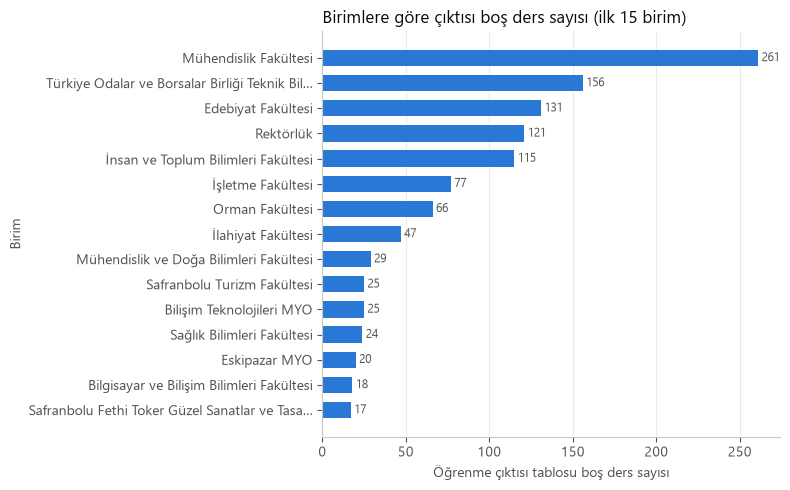

In [7]:
bos_birim = bos.groupby("birim").size().sort_values(ascending=False).head(15)
bos_birim = bos_birim.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([kisalt(b, 46) for b in bos_birim.index], bos_birim.values, color=MAVI, height=0.65)
for i, v in enumerate(bos_birim.values):
    ax.text(v + 2, i, str(v), va="center", fontsize=8.5, color=MUREKKEP2)
ax.set_xlabel("Öğrenme çıktısı tablosu boş ders sayısı")
ax.set_ylabel("Birim")
ax.set_title("Birimlere göre çıktısı boş ders sayısı (ilk 15 birim)", loc="left", color=MUREKKEP)
izgara(ax, "x")
plt.show()

Boş ders sayısı en yüksek birimler Mühendislik Fakültesi (261), TOBB Teknik Bilimler MYO (156) ve Edebiyat Fakültesi (131); bunlar aynı zamanda çok dersli birimler. Oran olarak bakınca Rektörlük, İlahiyat ve Orman fakülteleri öne çıkıyor (`doluluk.json`'daki oranlar); sayı ile oran farklı sıralama veriyor.

## 4. İngilizce cümleler

Bu adımda İngilizce yazılmış cümleleri ayırıyorum. Kalite kontrolü Türkçe cümleler için tasarlandı; İngilizce cümleye Türkçe ekler üzerinden kural uygulamak anlamsız sonuç verir. Bu yüzden bu cümleleri analizden çıkarıyorum. Ayırma kuralı basit: cümlede Türkçeye özgü harf (ç, ğ, ı, ö, ş, ü) yoksa ve içinde `the`, `and`, `will`, `students` gibi sık İngilizce sözcüklerden biri varsa İngilizce sayıyorum.

In [8]:
ing_mask = dolu["cumle"].map(ingilizce_mi)
ing = dolu[ing_mask]
T = dolu[~ing_mask].copy()   # Türkçe cümleler: bundan sonraki analizlerin temeli

print("İngilizce cümle:", sayi(len(ing)), f"(toplam cümlenin %{ondalik(100 * len(ing) / len(dolu), 2)})")
print("Analizde kalan Türkçe cümle:", sayi(len(T)))
print(ing["seviye"].value_counts().to_string())

İngilizce cümle: 214 (toplam cümlenin %0,31)
Analizde kalan Türkçe cümle: 68.972
seviye
Lisans       206
Ön Lisans      8


In [9]:
ing.sample(5, random_state=0)[["birim", "ders_adi", "cumle"]].assign(cumle=lambda d: d["cumle"].map(lambda s: kisa_metin(s, 100))).reset_index(drop=True)

,birim,ders_adi,cumle
0,MÜHENDİSLİK VE DOĞA BİLİMLERİ FAKÜLTESİ,Testing and Certification in Rail Systems,Makes corrections on systems that cannot pass testing and certification.
1,MÜHENDİSLİK VE DOĞA BİLİMLERİ FAKÜLTESİ,Precision Machine Design,Estimate safety factors of simple structures exposed to static and repeated loads.
2,EDEBİYAT FAKÜLTESİ,Western Thought,Produce individual interpretation and criticism of literary texts
3,MÜHENDİSLİK VE DOĞA BİLİMLERİ FAKÜLTESİ,Manufacturing Planning,Calculate capability of production capasity.
4,MÜHENDİSLİK FAKÜLTESİ,Cerrahi Enstrümantasyon,State purposes of surgical devices


İngilizce cümle sayısı toplamın yüzde 0,3'ü kadar (214); 206'sı lisans, 8'i ön lisans düzeyinde. Örnekler kuralın İngilizce cümleleri yakaladığını gösteriyor. Kural kaba olduğu için nadir bir İngilizce cümleyi kaçırmış ya da Türkçe harf içermeyen kısa bir Türkçe cümleyi yanlış ayırmış olabilirim; sayının küçüklüğü sonuçları değiştirmez.

## 5. Cümle uzunluğu

Bu adımda her Türkçe cümlenin kelime sayısını boşluklara göre buluyorum. Uzunluk, kalite için bir ipucu: çok kısa cümleler genellikle konu başlığı gibi duruyor ("çıktı değil" adayları).

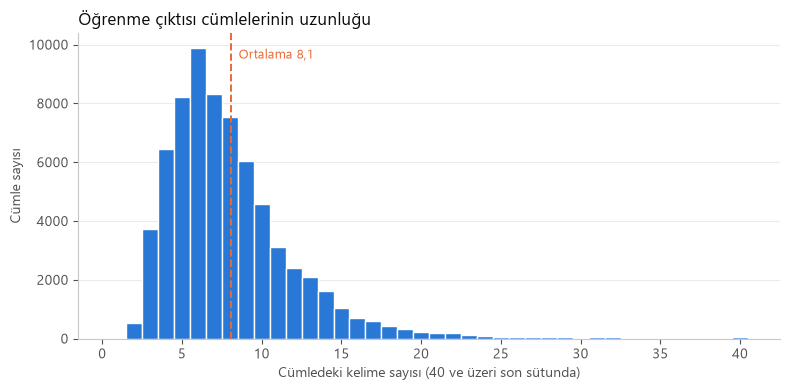

Ortalama 8,1 kelime | ortanca 7 kelime | 3 ve altı kelimeli cümle: 4.271


In [10]:
T["kelime"] = T["cumle"].str.split().str.len()
k = np.sort(T["kelime"].values)
ort, medyan = k.mean(), k[len(k) // 2]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(T["kelime"].clip(upper=40), bins=np.arange(0.5, 41.5, 1), color=MAVI, edgecolor="white")
ax.axvline(ort, color=TURUNCU, ls="--", lw=1.4)
ax.text(ort + 0.5, ax.get_ylim()[1] * 0.95, f"Ortalama {ondalik(ort)}", color=TURUNCU, fontsize=9, va="top")
ax.set_xlabel("Cümledeki kelime sayısı (40 ve üzeri son sütunda)")
ax.set_ylabel("Cümle sayısı")
ax.set_title("Öğrenme çıktısı cümlelerinin uzunluğu", loc="left", color=MUREKKEP)
izgara(ax)
plt.show()
print(f"Ortalama {ondalik(ort)} kelime | ortanca {medyan} kelime | 3 ve altı kelimeli cümle: {sayi((k <= 3).sum())}")

Dağılım sağa çarpık: cümlelerin yaklaşık yüzde 65'i 5-10 kelime arasında; ortalama ortancadan biraz yüksek çünkü az sayıda çok uzun cümle ortalamayı yukarı çekiyor. 3 kelime ve altındaki 4.271 cümle (yaklaşık yüzde 6) büyük olasılıkla başlık biçiminde yazılmış.

In [11]:
tek = T.drop_duplicates("cumle")
kisa = tek.nsmallest(5, "kelime")[["kelime", "cumle", "birim"]]
uzun = tek.nlargest(5, "kelime")[["kelime", "cumle", "birim"]]
for t in (kisa, uzun):
    t["cumle"] = t["cumle"].map(lambda s: kisa_metin(s, 120))
    t["birim"] = t["birim"].map(lambda s: kisalt(s, 30))
print("En kısa 5 cümle")
display(kisa.reset_index(drop=True))
print("En uzun 5 cümle (metin 120 karakterde kesildi)")
display(uzun.reset_index(drop=True))

En kısa 5 cümle


,kelime,cumle,birim
0,1,Metaller,Eskipazar MYO
1,1,Plastikler,Eskipazar MYO
2,1,Kompozitler,Eskipazar MYO
3,1,Seramikler,Eskipazar MYO
4,1,Planlama,Türkiye Odalar ve Borsalar Bi…


En uzun 5 cümle (metin 120 karakterde kesildi)


,kelime,cumle,birim
0,114,"Tek fazlı diyotlu doğrultucuların çalışmasını bilir, bunlara ait giriş ve çıkış dalga ...",Teknoloji Fakültesi
1,85,"Ağız ve Çene Kistleri, tanı değerlendirme, nedenleri, klasifikasyonu ve Tedavi yönteml...",Diş Hekimliği Fakültesi
2,76,Alanı ile ilgili konularda sahip olduğu temel bilgi ve beceriler düzeyinde düşünceleri...,Safranbolu Turizm Fakültesi
3,75,"Kur’an’ı herkesin kendine göre yorumlayamayacağını, Kur’an’ı tefsir etmek için “Tefsir...",Rektörlük
4,62,Müşteri kavramını çeşitli açılardan ele alır ve pazarlama bakış açısından çeşitli çıkr...,Mühendislik ve Doğa Bilimleri…


En kısa örnekler tek kelimelik konu başlıkları (örneğin malzeme adları); en uzun örnekler birden fazla çıktıyı tek cümlede birleştirmiş görünüyor.

## 6. Ders başına cümle sayısı

Bu adımda her dersin kaç öğrenme çıktısı yazdığını sayıyorum (ham veriden, boş olmayan tüm cümleler). Çok az ya da çok fazla çıktı yazılan dersler, kalitenin dersler arasında eşit olmadığını gösterebilir.

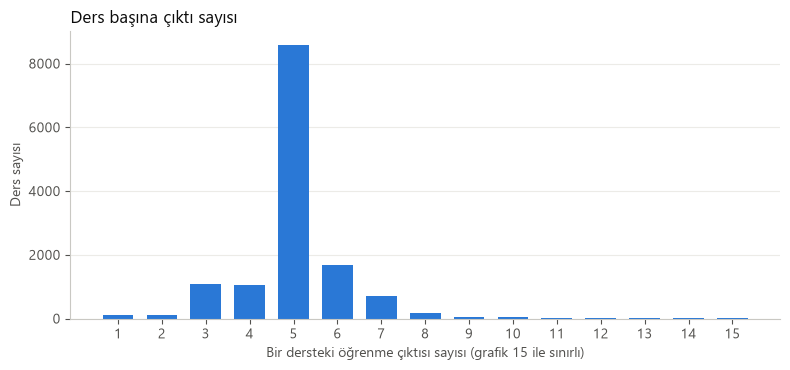

,Ders başına çıktı
Ders sayısı,13.702
Ortalama,"5,05"
Ortanca,5
En az,1
En çok,34
15'ten fazla çıktılı ders,1


In [12]:
ders_basina = dolu.groupby("ders_id").size()
v = np.sort(ders_basina.values)

fig, ax = plt.subplots(figsize=(8, 3.8))
xs = np.arange(1, 16)
sayac = ders_basina.value_counts()
ax.bar(xs, [sayac.get(x, 0) for x in xs], color=MAVI, width=0.7)
ax.set_xticks(xs)
ax.set_xlabel("Bir dersteki öğrenme çıktısı sayısı (grafik 15 ile sınırlı)")
ax.set_ylabel("Ders sayısı")
ax.set_title("Ders başına çıktı sayısı", loc="left", color=MUREKKEP)
izgara(ax)
plt.show()

ozet = pd.Series({"Ders sayısı": sayi(len(v)), "Ortalama": ondalik(v.mean(), 2), "Ortanca": v[len(v) // 2],
                  "En az": v.min(), "En çok": v.max(), "15'ten fazla çıktılı ders": sayi((v > 15).sum())}, name="Ders başına çıktı")
ozet.to_frame()

Bir derste ortalama yaklaşık 5 çıktı var ve dersler 5 çıktıda belirgin biçimde yığılıyor (13.702 dersin 8.581'i, yaklaşık yüzde 63). Uç değerler az sayıda ders: 118 dersin tek çıktısı var, en çok çıktısı olan ders 34 çıktı içeriyor.

## 7. Tekrar eden cümleler

Bu adımda aynı cümlenin kaç kez geçtiğine bakıyorum. Cümleleri küçük harfe çevirip fazla boşluk, nokta ve virgülü atıyorum (`sadelestir`); böylece yalnız biçim farkı olan cümleler aynı sayılıyor. Aynı cümle farklı derslerde tekrar ediyorsa bu genelde ortak ders şablonundan kaynaklanıyor; aynı ders içinde tekrar ise veri girişi hatası.

In [13]:
T["norm"] = T["cumle"].map(sadelestir)
sayac_cumle = T["norm"].value_counts()

tekrar_ozet = pd.DataFrame({
    "Gösterge": ["Türkçe cümle satırı", "Benzersiz cümle", "Birden çok kez geçen cümlelerin toplam satırı"],
    "Değer": [sayi(len(T)), sayi(len(sayac_cumle)), sayi(sayac_cumle[sayac_cumle > 1].sum())],
})
tekrar_ozet

,Gösterge,Değer
0,Türkçe cümle satırı,68.972
1,Benzersiz cümle,32.348
2,Birden çok kez geçen cümlelerin toplam satırı,49.860


Türkçe cümle satırlarının yaklaşık yüzde 72'si (49.860 satır) başka bir satırla birebir aynı; benzersiz cümle sayısı satır sayısının yarısından az. Yani veri, farklı derslere kopyalanmış ortak cümlelerle dolu.

In [14]:
ders_say = T.groupby("norm")["ders_id"].nunique().sort_values(ascending=False).head(5)
en_cok = pd.DataFrame({"Cümle (küçük harf, sadeleştirilmiş)": ders_say.index, "Kaç farklı derste": ders_say.values})
en_cok

,"Cümle (küçük harf, sadeleştirilmiş)",Kaç farklı derste
0,öğrenciler hedef dile karşı pozitif bir tutum geliştireceklerdir,246
1,güncel gelişmeleri geçmişin koşullarıyla karşılaştırarak değerlendirir,163
2,türk dış politikasının temel nitelikleri hakkında fikir sahibi olur,163
3,yakın dönem türkiye tarihi hakkında bilgi sahibi olur,163
4,atatürk i̇lkeleri ni tarihsel perspektif içinde değerlendirir,162


En çok tekrar eden cümleler yabancı dil, Türk dış politikası, yakın dönem tarihi ve Atatürk ilkeleri konularında; her biri 160-250 farklı derste aynen yer alıyor.

In [15]:
ders_ici = T.groupby(["ders_id", "norm"]).size()
fazla = ders_ici[ders_ici > 1]
print("Aynı ders içinde tekrar eden cümleye sahip ders sayısı:", sayi(fazla.index.get_level_values(0).nunique()))
print("Bu derslerdeki fazladan (tekrar) satır sayısı:", sayi((fazla - 1).sum()))

Aynı ders içinde tekrar eden cümleye sahip ders sayısı: 265
Bu derslerdeki fazladan (tekrar) satır sayısı: 458


Aynı ders içinde tekrar, 265 derste toplam 458 fazladan satır. Bu, 69 bin satırlık verinin çok küçük bir kısmı; yine de ders sayfasındaki girişin kopyalanıp yapıştırıldığını gösteriyor.

## 8. En sık son kelimeler (fiil yaklaşığı)

Türkçede yüklem cümle sonunda durur. Bu yüzden her cümlenin son kelimesini fiil yerine kullanıyorum; bu yaklaşık bir ölçü, her son kelime gerçek bir fiil değil. Amaç, yazarların hangi eylemleri sık kullandığını görmek. "Bilir", "öğrenir", "kavrar", "anlar", "olur", "edinir", "kazanır" gibi gözlemlenemeyen eylemleri turuncu çiziyorum; bunlar çıktıyı belirsiz yapma eğilimi taşıyor.

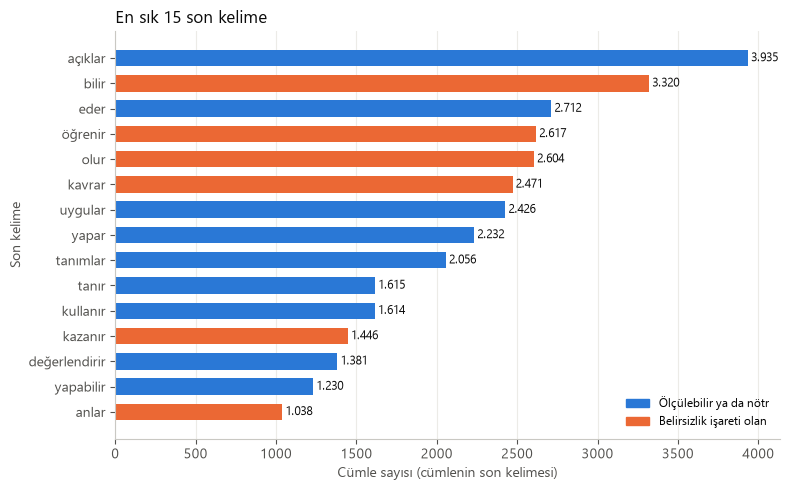

In [16]:
son = T["cumle"].map(son_kelime).value_counts().head(15).iloc[::-1]
belirsiz_isaret = re.compile(r"^(bilir|öğrenir|kavrar|anlar|olur|edinir|kazanır)$")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(son.index, son.values, color=[TURUNCU if belirsiz_isaret.match(w) else MAVI for w in son.index], height=0.65)
for i, c in enumerate(son.values):
    ax.text(c + 20, i, sayi(c), va="center", fontsize=8.5, color=MUREKKEP)
ax.set_xlabel("Cümle sayısı (cümlenin son kelimesi)")
ax.set_ylabel("Son kelime")
ax.set_title("En sık 15 son kelime", loc="left", color=MUREKKEP)
ax.legend(handles=[Patch(color=MAVI, label="Ölçülebilir ya da nötr"), Patch(color=TURUNCU, label="Belirsizlik işareti olan")],
          frameon=False, fontsize=8.5, loc="lower right")
izgara(ax, "x")
plt.show()

İlk 15 son kelimenin 6'sı belirsizlik işareti taşıyor (bilir, öğrenir, olur, kavrar, kazanır, anlar) ve bunlar birlikte yaklaşık 13.500 cümlenin sonunda duruyor. "Açıklar", "uygular", "tanımlar" gibi ölçülebilir eylemler de çok sık; en çok kullanılan kelime "açıklar".

## 9. Birimlere göre cümle sayısı

Bu adımda her birimin toplam cümle sayısına bakıyorum. Sonraki bölümlerde birimleri oranla karşılaştıracağım; bu grafik hangi birimin oranının daha sağlam (çok cümleye dayalı), hangisinin daha oynak (az cümleli) olduğunu görmek için.

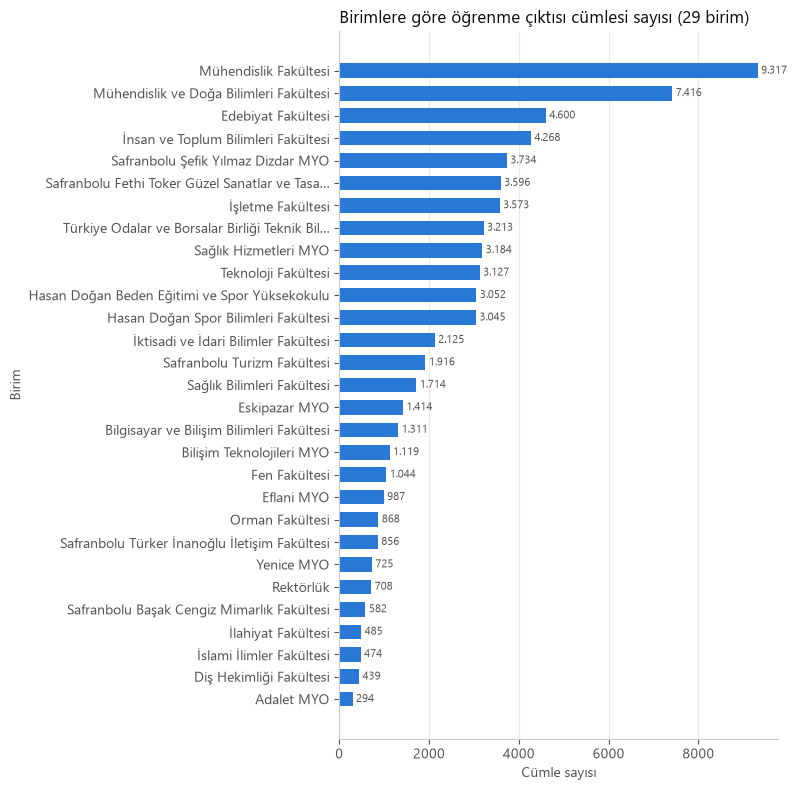

In [17]:
birim_cumle = dolu.groupby("birim").size().sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh([kisalt(b, 46) for b in birim_cumle.index], birim_cumle.values, color=MAVI, height=0.65)
for i, v_ in enumerate(birim_cumle.values):
    ax.text(v_ + 80, i, sayi(v_), va="center", fontsize=8, color=MUREKKEP2)
ax.set_xlabel("Cümle sayısı")
ax.set_ylabel("Birim")
ax.set_title("Birimlere göre öğrenme çıktısı cümlesi sayısı (29 birim)", loc="left", color=MUREKKEP)
izgara(ax, "x")
plt.show()

Birimler arasında büyük fark var: Mühendislik Fakültesi ve Mühendislik ve Doğa Bilimleri Fakültesi dokuz bin ve yedi bin cümleye yakın, en küçük birimler birkaç yüz cümle. Küçük birimlerin oranları az sayıya dayandığı için dalgalı olabilir.

## 10. Etiketli örnek (795 cümle)

Bu adımda elle onaylanmış cevap anahtarına bakıyorum. 795 cümle beş gruptan oluşuyor: vize raporundaki ilk 300 cümle (`ILK_300`) ve final için seçtiğim dört grup. Gruplar farklı amaçla seçildi: `RASTGELE` havuzdan rastgele çekilen 100 cümle (test seti), `CIKTI_DEGIL_ADAY` kuralın "çıktı değil" dediği cümlelerden rastgele, `KALITE_KARARSIZ` kalite modelinin en kararsız kaldığı cümleler, `BLOOM` ise Bloom basamağını zorlayan cümleler (kararsız olanlar ve üst düzey tahmin edilenler).

In [18]:
et = pd.read_csv(YOL_ETIKET, encoding="utf-8-sig", dtype=str, keep_default_na=False)
grup_sira = ["ILK_300", "RASTGELE", "CIKTI_DEGIL_ADAY", "KALITE_KARARSIZ", "BLOOM"]
g = et["secim_grubu"].value_counts().reindex(grup_sira)
grup_tablo = pd.DataFrame({"Cümle sayısı": g})
grup_tablo.loc["Toplam"] = g.sum()
grup_tablo

,Cümle sayısı
secim_grubu,
ILK_300,300
RASTGELE,100
CIKTI_DEGIL_ADAY,145
KALITE_KARARSIZ,150
BLOOM,100
Toplam,795


Beş grubun toplamı 795. Yalnız `RASTGELE` grubu rastgele örnek; diğerleri bilerek zor ya da nadir cümlelere yönelik seçildi. Bu yüzden aşağıdaki dağılımlar üniversitenin genel dağılımı olarak okunmamalı.

In [19]:
kal = et["alptekin_kalite"].value_counts().reindex(KALITE)
blm = et.loc[et["alptekin_bloom"] != "", "alptekin_bloom"].value_counts().reindex(BLOOM).fillna(0).astype(int)

tablo_k = pd.DataFrame({"Sınıf": [KALITE_AD[k] for k in KALITE], "Cümle": kal.values,
                        "Yüzde": (100 * kal.values / kal.sum()).round(1)})
tablo_b = pd.DataFrame({"Bloom basamağı": BLOOM_AD, "Cümle": blm.values,
                        "Yüzde": (100 * blm.values / blm.sum()).round(1)})
display(tablo_k)
display(tablo_b)

,Sınıf,Cümle,Yüzde
0,Düzgün,405,50.9
1,Belirsiz,239,30.1
2,Çıktı değil,151,19.0


,Bloom basamağı,Cümle,Yüzde
0,Hatırlama,44,10.9
1,Anlama,85,21.0
2,Uygulama,120,29.6
3,Analiz,70,17.3
4,Değerlendirme,27,6.7
5,Yaratma,45,11.1
6,Bilişsel değil,14,3.5


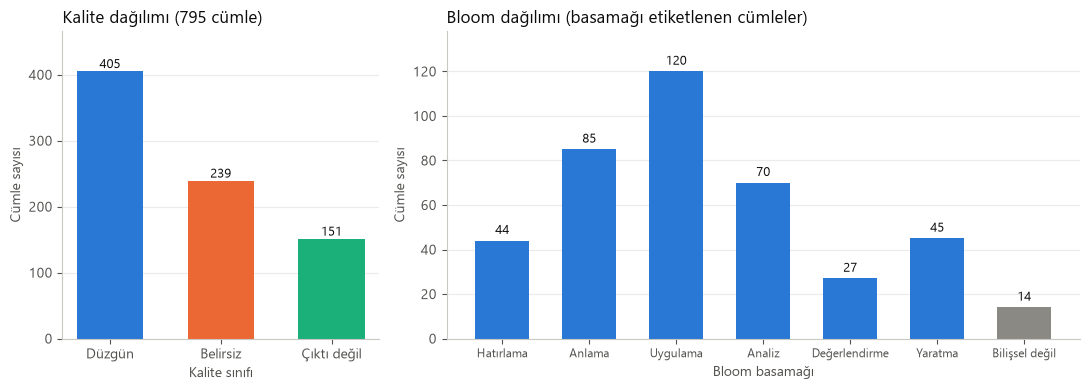

In [20]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})

ax = eksenler[0]
b = ax.bar([KALITE_AD[k] for k in KALITE], kal.values, color=[MAVI, TURUNCU, YESIL], width=0.6)
for r, v_ in zip(b, kal.values):
    ax.text(r.get_x() + r.get_width() / 2, v_ + 5, str(v_), ha="center", fontsize=9, color=MUREKKEP)
ax.set_xlabel("Kalite sınıfı")
ax.set_ylabel("Cümle sayısı")
ax.set_title("Kalite dağılımı (795 cümle)", loc="left", color=MUREKKEP)
ax.set_ylim(0, kal.max() * 1.15)
izgara(ax)

ax = eksenler[1]
b = ax.bar(BLOOM_AD, blm.values, color=[MAVI] * 6 + [GRI], width=0.62)
for r, v_ in zip(b, blm.values):
    ax.text(r.get_x() + r.get_width() / 2, v_ + 3, str(v_), ha="center", fontsize=9, color=MUREKKEP)
ax.set_xlabel("Bloom basamağı")
ax.set_ylabel("Cümle sayısı")
ax.set_title("Bloom dağılımı (basamağı etiketlenen cümleler)", loc="left", color=MUREKKEP)
ax.set_ylim(0, blm.max() * 1.15)
ax.tick_params(axis="x", labelsize=8.5)
izgara(ax)
plt.show()

Etiketli örnekte düzgün cümleler çoğunlukta, belirsiz ikinci, çıktı değil en az. Bloom tarafında uygulama ve anlama basamakları öne çıkıyor. Çıktı değil sınıfı örnekte kasıtlı olarak fazla temsil ediliyor (`CIKTI_DEGIL_ADAY` grubu yüzünden), bu yüzden gerçek veride bu sınıfın payı çok daha küçük (bölüm 11).

## 11. Modelin bütün veriye verdiği etiketler

Bu adımda modelin 69.186 cümleye verdiği etiketleri okuyorum. İngilizce cümleler `INGILIZCE` etiketiyle ayrılmış; bunları çıkarınca 68.972 cümle kalıyor. "Sorunlu" cümle, belirsiz ile çıktı değil sınıflarının toplamı. Bloom oranlarını yalnız düzgün cümleler içinde hesaplıyorum, çünkü Bloom basamağı yalnız düzgün cümlelere veriliyor.

In [21]:
tum = pd.read_csv(YOL_TUM, encoding="utf-8-sig", dtype=str, keep_default_na=False)
tum_ing = tum[tum["kalite"] == "INGILIZCE"]
d = tum[tum["kalite"] != "INGILIZCE"].copy()
d["sorunlu"] = d["kalite"].isin(["BELIRSIZ", "CIKTI_DEGIL"]).astype(int)

kal_say = tum["kalite"].value_counts()
kal_tablo = pd.DataFrame({
    "Sınıf": [KALITE_AD[k] for k in KALITE] + ["İngilizce (analiz dışı)"],
    "Cümle": [kal_say[k] for k in KALITE] + [kal_say["INGILIZCE"]],
})
kal_tablo["Yüzde (İngilizce hariç)"] = [round(100 * kal_say[k] / len(d), 1) for k in KALITE] + [np.nan]
kal_tablo["Cümle"] = kal_tablo["Cümle"].map(sayi)
print("Toplam satır:", sayi(len(tum)), "| İngilizce hariç:", sayi(len(d)))
kal_tablo

Toplam satır: 69.186 | İngilizce hariç: 68.972


,Sınıf,Cümle,Yüzde (İngilizce hariç)
0,Düzgün,46.076,66.8
1,Belirsiz,20.816,30.2
2,Çıktı değil,2.080,3.0
3,İngilizce (analiz dışı),214,NaN


Modele göre cümlelerin yaklaşık üçte ikisi düzgün, üçte biri belirsiz ya da çıktı değil. Çıktı değil sınıfı yüzde 3 civarında; asıl sorun, ölçülemeyen "bilir / öğrenir" tarzı belirsiz cümleler.

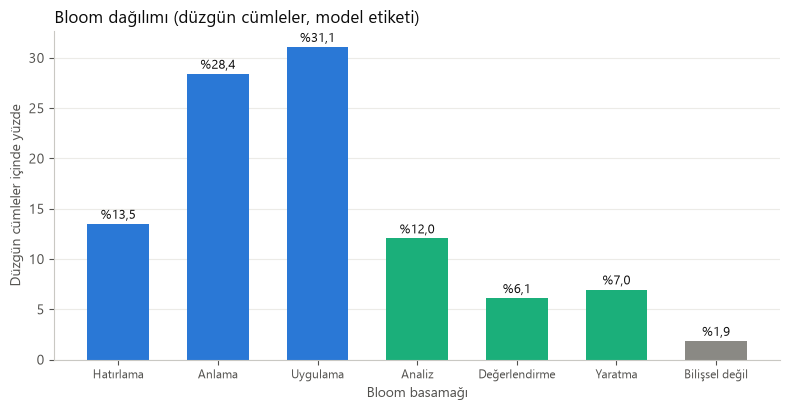

Üst basamaklar (analiz + değerlendirme + yaratma): 11.581 cümle, düzgün cümlelerin %25,1'i


In [22]:
duzgun = d[d["kalite"] == "DUZGUN"]
bloom_say = duzgun["bloom"].value_counts().reindex(BLOOM).fillna(0).astype(int)
bloom_yuzde = 100 * bloom_say / bloom_say.sum()

fig, ax = plt.subplots(figsize=(8, 4.2))
b = ax.bar(BLOOM_AD, bloom_yuzde.values, color=[MAVI] * 3 + [YESIL] * 3 + [GRI], width=0.62)
for r, v_ in zip(b, bloom_yuzde.values):
    ax.text(r.get_x() + r.get_width() / 2, v_ + 0.5, f"%{ondalik(v_)}", ha="center", fontsize=9, color=MUREKKEP)
ax.set_xlabel("Bloom basamağı")
ax.set_ylabel("Düzgün cümleler içinde yüzde")
ax.set_title("Bloom dağılımı (düzgün cümleler, model etiketi)", loc="left", color=MUREKKEP)
ax.tick_params(axis="x", labelsize=8.5)
izgara(ax)
plt.show()
ust = bloom_say[["ANALIZ", "DEGERLENDIRME", "YARATMA"]].sum()
print(f"Üst basamaklar (analiz + değerlendirme + yaratma): {sayi(ust)} cümle, düzgün cümlelerin %{ondalik(100 * ust / bloom_say.sum(), 1)}'i")

Düzgün cümlelerin çoğu uygulama ve anlama basamağında. Analiz, değerlendirme ve yaratma gibi üst basamaklar toplamda dörtte bire yakın. Bu oranlar modelin etiketine dayanıyor; model Bloom'da kalitede olduğu kadar güçlü değil (bölüm 12), bu yüzden tek tek cümle için değil genel eğilim olarak okuyorum.

In [23]:
sv = d.groupby("seviye").apply(lambda g: pd.Series({
    "Cümle": len(g),
    "Düzgün %": 100 * (g["kalite"] == "DUZGUN").mean(),
    "Belirsiz %": 100 * (g["kalite"] == "BELIRSIZ").mean(),
    "Çıktı değil %": 100 * (g["kalite"] == "CIKTI_DEGIL").mean(),
    "Sorunlu %": 100 * g["sorunlu"].mean(),
    "Üst basamak % (düzgünler içinde)": 100 * g.loc[g["kalite"] == "DUZGUN", "bloom"].isin(["ANALIZ", "DEGERLENDIRME", "YARATMA"]).mean(),
}))
sv["Cümle"] = sv["Cümle"].astype(int).map(sayi)
sv.round(1)

,Cümle,Düzgün %,Belirsiz %,Çıktı değil %,Sorunlu %,Üst basamak % (düzgünler içinde)
seviye,,,,,,
Lisans,54.310,67.8,29.2,3.0,32.2,27.0
Ön Lisans,14.662,63.2,33.9,2.9,36.8,17.8


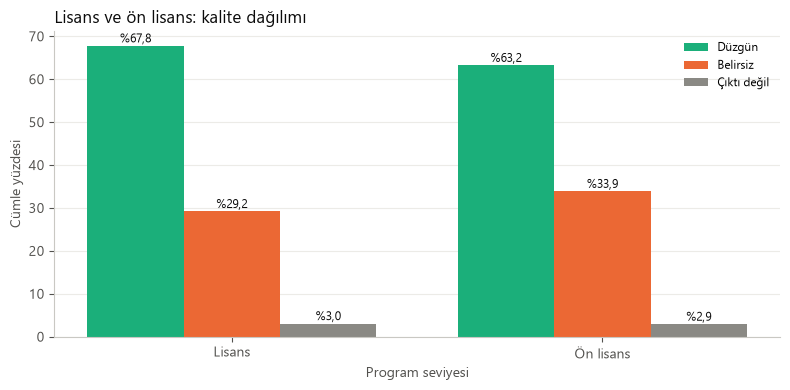

In [24]:
sv_ham = d.groupby("seviye")["kalite"].value_counts(normalize=True).mul(100).unstack()[KALITE]
sv_ham = sv_ham.loc[["Lisans", "Ön Lisans"]]

fig, ax = plt.subplots(figsize=(8, 4))
genislik = 0.26
for i, (k, renk) in enumerate(zip(KALITE, [YESIL, TURUNCU, GRI])):
    xs = np.arange(2) + (i - 1) * genislik
    ax.bar(xs, sv_ham[k].values, genislik, color=renk, label=KALITE_AD[k])
    for x_, v_ in zip(xs, sv_ham[k].values):
        ax.text(x_, v_ + 0.8, f"%{ondalik(v_)}", ha="center", fontsize=8.5, color=MUREKKEP)
ax.set_xticks(range(2))
ax.set_xticklabels(["Lisans", "Ön lisans"])
ax.set_xlabel("Program seviyesi")
ax.set_ylabel("Cümle yüzdesi")
ax.set_title("Lisans ve ön lisans: kalite dağılımı", loc="left", color=MUREKKEP)
ax.legend(frameon=False, fontsize=8.5)
izgara(ax)
plt.show()

Ön lisansta sorunlu cümle oranı lisanstan birkaç puan yüksek. Üst basamak oranındaki fark daha büyük: ön lisans cümleleri daha çok uygulama basamağında, lisans cümleleri daha çok analiz ve üstünde. Bu fark, iki seviyenin hedeflerinin farklı olmasıyla da uyumlu; sorunlu oranı farkı ise yazım kalitesine işaret ediyor.

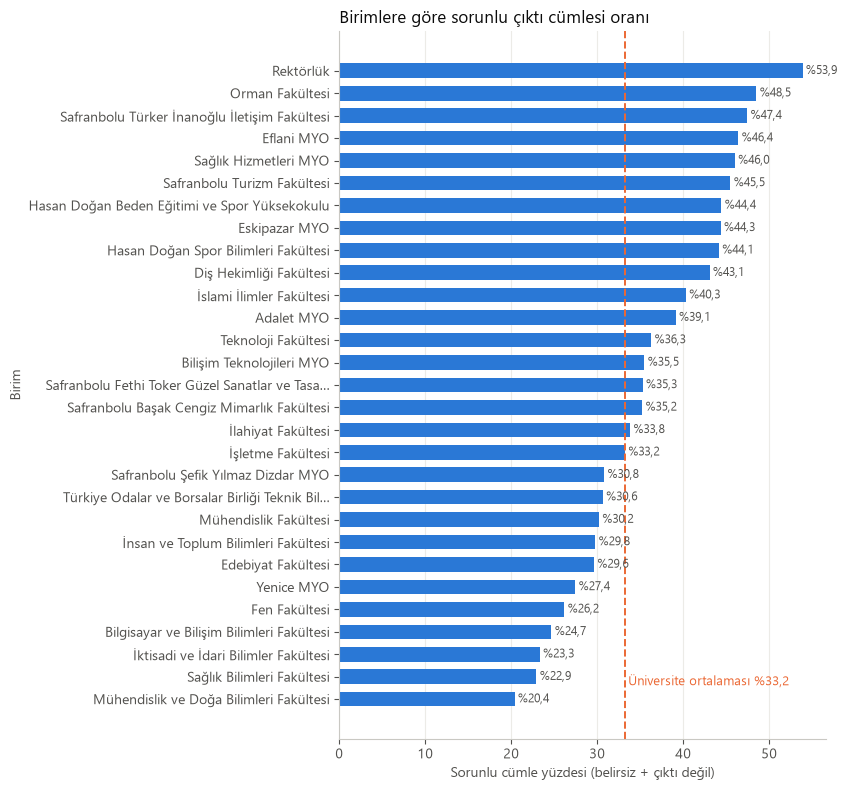

In [25]:
birim_tablo = d.groupby("birim").agg(cumle=("kalite", "size"), sorunlu=("sorunlu", "mean"))
birim_tablo["sorunlu"] *= 100
birim_tablo = birim_tablo.sort_values("sorunlu")
uni_ort = 100 * d["sorunlu"].mean()

fig, ax = plt.subplots(figsize=(8.5, 8))
ax.barh([kisalt(b, 46) for b in birim_tablo.index], birim_tablo["sorunlu"], color=MAVI, height=0.65)
for i, v_ in enumerate(birim_tablo["sorunlu"]):
    ax.text(v_ + 0.4, i, f"%{ondalik(v_)}", va="center", fontsize=8.5, color=MUREKKEP2)
ax.axvline(uni_ort, color=TURUNCU, ls="--", lw=1.4)
ax.text(uni_ort + 0.4, 0.5, f"Üniversite ortalaması %{ondalik(uni_ort)}", color=TURUNCU, fontsize=9, va="bottom")
ax.set_xlabel("Sorunlu cümle yüzdesi (belirsiz + çıktı değil)")
ax.set_ylabel("Birim")
ax.set_title("Birimlere göre sorunlu çıktı cümlesi oranı", loc="left", color=MUREKKEP)
izgara(ax, "x")
plt.show()

Birimler arasında sorunlu oranı çok değişiyor; ortalamanın çok üstünde kalan birimler de, çok altında kalanlar da var. Küçük birimlerin oranları az cümleye dayandığı için (bölüm 9) dikkatli okunmalı.

In [26]:
prog = d.groupby(["birim", "program", "seviye"]).agg(cumle=("kalite", "size"), sorunlu=("sorunlu", "mean")).reset_index()
prog["sorunlu"] = (100 * prog["sorunlu"]).round(1)
buyuk = prog[prog["cumle"] >= 100].copy()
buyuk["birim"] = buyuk["birim"].map(lambda s: kisalt(s, 34))
buyuk = buyuk.rename(columns={"cumle": "cümle", "sorunlu": "sorunlu %"})
print("En az 100 cümleli program sayısı:", len(buyuk))
print("Sorunlu oranı en yüksek 5 program")
display(buyuk.sort_values("sorunlu %", ascending=False).head(5).reset_index(drop=True))
print("Sorunlu oranı en düşük 5 program")
display(buyuk.sort_values("sorunlu %").head(5).reset_index(drop=True))

En az 100 cümleli program sayısı: 168
Sorunlu oranı en yüksek 5 program


,birim,program,seviye,cümle,sorunlu %
0,Eskipazar MYO,Özel Güvenlik ve Koruma,Ön Lisans,183,62.3
1,Eflani MYO,Atçılık ve Antrenörlüğü,Ön Lisans,281,58.7
2,Eflani MYO,Gıda Kalite Kontrolü ve Analizi,Ön Lisans,252,58.3
3,İktisadi ve İdari Bilimler Fakült…,Sosyal Hizmet,Lisans,317,55.5
4,Sağlık Hizmetleri MYO,Otopsi Yardımcılığı,Ön Lisans,229,54.6


Sorunlu oranı en düşük 5 program


,birim,program,seviye,cümle,sorunlu %
0,Mühendislik ve Doğa Bilimleri Fak…,Biyomedikal Mühendisliği,Lisans,737,10.0
1,Mühendislik ve Doğa Bilimleri Fak…,Mekatronik Mühendisliği,Lisans,509,10.6
2,Mühendislik ve Doğa Bilimleri Fak…,Matematik,Lisans,424,11.1
3,Mühendislik ve Doğa Bilimleri Fak…,Elektrik - Elektronik Mühendisliği (%30 İngilizce),Lisans,511,11.2
4,Yenice MYO,Bilgisayar Programcılığı,Ön Lisans,197,12.2


En yüksek ve en düşük programlar arasında büyük fark var: en yüksek programlarda cümlelerin yüzde 55-62'si sorunlu, en düşüklerde yaklaşık yüzde 10-12'si. Bu 168 program 100'den fazla cümleye sahip olduğundan oranlar makul ölçüde sağlam. Yüksek tarafta ön lisans (MYO) programları, düşük tarafta mühendislik programları ağırlıkta.

## 12. Yöntemlerin karşılaştırması (aynı 100 test cümlesi)

Bu adımda altı yöntemi aynı 100 test cümlesinde karşılaştırıyorum. Kural, TF-IDF ve BERTurk sonuçlarını daha önce hesaplanıp kaydedilmiş `sonuc_02/03/04.json` dosyalarından okuyorum (bu defterde eğitim yok). GPT-6.1 Sol ve Claude Haiku sonuçlarını ise tahmin dosyalarından kendim hesaplıyorum: tahminleri cevap anahtarındaki `RASTGELE` grubuyla (100 cümle) `no` sütunu üzerinden eşleştiriyorum.

Kalite için doğruluk ve macro-F1 (3 sınıf) hesaplıyorum. Bloom için yalnız cevap anahtarında düzgün olan ve modelin de düzgün dediği cümlelere bakıyorum; macro-F1'de 7 Bloom sınıfını `labels` olarak veriyorum ve eksik sınıf için `zero_division=0` kullanıyorum.

In [27]:
test = et[et["secim_grubu"] == "RASTGELE"].set_index("no")
print("Test cümlesi:", len(test), "| cevap anahtarı kalite dağılımı:", test["alptekin_kalite"].value_counts().to_dict())


def llm_skorlari(yol):
    t = pd.read_csv(yol, dtype=str, keep_default_na=False).set_index("no")
    t = t.loc[test.index]                       # aynı 100 cümle, aynı sıra
    kal_dogruluk = accuracy_score(test["alptekin_kalite"], t["kalite"])
    kal_f1 = f1_score(test["alptekin_kalite"], t["kalite"], labels=KALITE, average="macro", zero_division=0)
    ortak = (test["alptekin_kalite"] == "DUZGUN") & (t["kalite"] == "DUZGUN")
    b_dogruluk = accuracy_score(test.loc[ortak, "alptekin_bloom"], t.loc[ortak, "bloom"])
    b_f1 = f1_score(test.loc[ortak, "alptekin_bloom"], t.loc[ortak, "bloom"], labels=BLOOM, average="macro", zero_division=0)
    return {"kalite_dogruluk": kal_dogruluk, "kalite_f1": kal_f1, "bloom_dogruluk": b_dogruluk, "bloom_f1": b_f1, "bloom_n": int(ortak.sum())}


gpt = llm_skorlari(YOL_GPT)
haiku = llm_skorlari(YOL_HAIKU)
print("GPT-6.1 Sol  :", {k: round(v, 3) if isinstance(v, float) else v for k, v in gpt.items()})
print("Claude Haiku :", {k: round(v, 3) if isinstance(v, float) else v for k, v in haiku.items()})

Test cümlesi: 100 | cevap anahtarı kalite dağılımı: {'DUZGUN': 63, 'BELIRSIZ': 30, 'CIKTI_DEGIL': 7}
GPT-6.1 Sol  : {'kalite_dogruluk': 0.98, 'kalite_f1': 0.984, 'bloom_dogruluk': 0.871, 'bloom_f1': 0.846, 'bloom_n': 62}
Claude Haiku : {'kalite_dogruluk': 0.97, 'kalite_f1': 0.975, 'bloom_dogruluk': 0.903, 'bloom_f1': 0.878, 'bloom_n': 62}


İki büyük modelin sayıları tahmin dosyalarından geldi, JSON dosyalarından değil. Bloom skorları, her modelin kendi "düzgün" dediği cümlelerde hesaplandığı için cümle sayıları birbirinden bir iki cümle farklı olabilir (`bloom_n`).

In [28]:
def json_oku(yol):
    with open(yol, encoding="utf-8") as f:
        return json.load(f)


s2, s3, s4 = json_oku("sonuc_02.json"), json_oku("sonuc_03.json"), json_oku("sonuc_04.json")
kt, bt = s2["kalite_test"], s2["bloom_test"]
SVM, LOJ = "TF-IDF + SVM | ILK_300_ve_yeni", "TF-IDF + lojistik regresyon | ILK_300_ve_yeni"

satirlar = [
    ("Kural", kt["Kural"]["dogruluk"], kt["Kural"]["macro_f1"], np.nan, np.nan),
    ("TF-IDF + SVM", kt[SVM]["dogruluk"], kt[SVM]["macro_f1"], bt[SVM]["dogruluk"], bt[SVM]["macro_f1"]),
    ("TF-IDF + lojistik", kt[LOJ]["dogruluk"], kt[LOJ]["macro_f1"], bt[LOJ]["dogruluk"], bt[LOJ]["macro_f1"]),
    ("BERTurk", s3["berturk"]["kalite"]["dogruluk_ort"], s3["berturk"]["kalite"]["macro_f1_ort"],
     s4["test_dogruluk_ort"], s4["test_macro_f1_ort"]),
    ("GPT-6.1 Sol", gpt["kalite_dogruluk"], gpt["kalite_f1"], gpt["bloom_dogruluk"], gpt["bloom_f1"]),
    ("Claude Haiku", haiku["kalite_dogruluk"], haiku["kalite_f1"], haiku["bloom_dogruluk"], haiku["bloom_f1"]),
]
kars = pd.DataFrame(satirlar, columns=["Yöntem", "Kalite doğruluk", "Kalite macro-F1", "Bloom doğruluk", "Bloom macro-F1"]).set_index("Yöntem")
kars.round(3)

,Kalite doğruluk,Kalite macro-F1,Bloom doğruluk,Bloom macro-F1
Yöntem,,,,
Kural,0.910,0.881,NaN,NaN
TF-IDF + SVM,0.870,0.810,0.683,0.543
TF-IDF + lojistik,0.870,0.800,0.698,0.569
BERTurk,0.963,0.956,0.721,0.622
GPT-6.1 Sol,0.980,0.984,0.871,0.846
Claude Haiku,0.970,0.975,0.903,0.878


Kalite tarafında BERTurk, GPT ve Haiku yüzde 95'in üstünde; kural tabanlı yöntem ve TF-IDF geride. Bloom tarafında fark çok daha büyük: TF-IDF ve BERTurk yüzde 70 civarında, iki büyük model belirgin biçimde daha yüksek. Kural yöntemi Bloom basamağı üretmediği için o hücreler boş. Tabloyu okurken ölçülen cümle kümelerinin biraz farklı olduğunu unutmamak gerekiyor (aşağıdaki not).

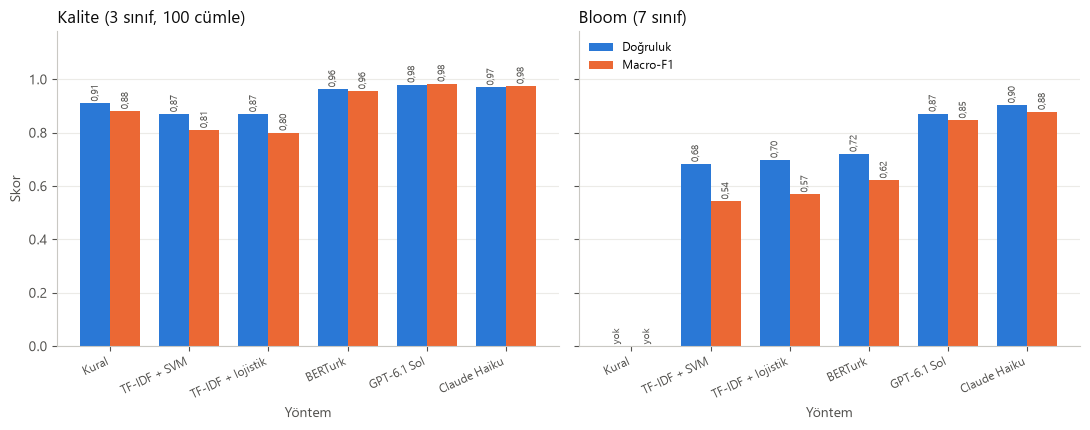

In [29]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
adlar = list(kars.index)
x = np.arange(len(adlar))
w = 0.38
for ax, (baslik, d_kol, f_kol) in zip(eksenler, [("Kalite (3 sınıf, 100 cümle)", "Kalite doğruluk", "Kalite macro-F1"),
                                                  ("Bloom (7 sınıf)", "Bloom doğruluk", "Bloom macro-F1")]):
    for j, (kol, renk, ad) in enumerate([(d_kol, MAVI, "Doğruluk"), (f_kol, TURUNCU, "Macro-F1")]):
        degerler = kars[kol].values
        cubuk = ax.bar(x + (j - 0.5) * w, np.nan_to_num(degerler), w, color=renk, label=ad)
        for xi, v_ in zip(x + (j - 0.5) * w, degerler):
            ax.text(xi, (0 if np.isnan(v_) else v_) + 0.015, "yok" if np.isnan(v_) else ondalik(v_, 2),
                    ha="center", fontsize=7.5, color=MUREKKEP2, rotation=90)
    ax.set_xticks(x)
    ax.set_xticklabels(adlar, rotation=25, ha="right", fontsize=8.5)
    ax.set_ylim(0, 1.18)
    ax.set_xlabel("Yöntem")
    ax.set_title(baslik, loc="left", color=MUREKKEP)
    izgara(ax)
eksenler[0].set_ylabel("Skor")
eksenler[1].legend(frameon=False, fontsize=8.5, loc="upper left")
plt.show()

Grafik tablodaki sıralamayı doğruluyor: kalitede yöntemler birbirine yakın ve yüksek; Bloom'da klasik yöntemlerle büyük modeller arasında açık fark var.

Not: Kural / TF-IDF / BERTurk kalite ölçümleri aynı 100 cümlede, ama Bloom ölçümleri kalite etiketi doğru olan 63 cümlede yapılmıştı. GPT ve Haiku'nun Bloom skoru ise cevap anahtarında ve modelde düzgün çıkan cümlelerde hesaplandı. Üç grup aynı 100 cümleden geliyor ama Bloom için cümle kümeleri birebir aynı değil; karşılaştırma yaklaşık bir sıralama verir. BERTurk skorları birkaç farklı rastgele başlangıcın (tohum) ortalamasıdır. Claude Haiku Bloom değeri `haiku2_tahmin.csv` dosyasından hesaplandı; daha önceki Haiku çalışmasını anlatan `sonuc_05.json`'daki değerden (0,968) farklıdır.

## 13. Sınırlar

- Etiketler, yapay zekâ önerisi görülerek onaylandı; bağımsız bir ikinci etiketleme yapılmadı. Bu yüzden etiketleyici uyumu ölçülemedi ve cevap anahtarı yapay zekâ önerisine yakın olabilir.
- Cevap anahtarının önerisi bir Claude modelinden (Sonnet) geldi; Claude Haiku aynı aileden. Haiku'nun yüksek skoru bu yakınlıktan şişmiş olabilir.
- Bloom'da modelin doğruluğu yaklaşık yüzde 72 (100 cümlede yaklaşık 72 doğru). Bu yüzden birim ve program düzeyindeki Bloom oranları kesin değer değil, genel eğilim olarak okunmalı.
- Veri tek üniversitenin (Karabük) bilgi paketinden geliyor; sonuçlar başka üniversitelere doğrudan genellenemez.